In [1]:
# V5 prerequisite check; no fallback to historical outputs.
from pathlib import Path
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
V5_ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5'),Path('/content/drive/MyDrive/Musanga/Final/V5')] if (p.parent/'Data').is_dir()),None)
assert V5_ROOT is not None, 'Permanent Final/Data not found'
required=["03_unified_rgb_unet_v5/03_training_contract.json","01_spatial_cover_folds_v2/01_reference_fold_contract_v2.json","02_rgb_circles_plus_plots_v3/02_reference_mosaic_owners_v2.csv"]
missing=[str(V5_ROOT/'Outputs'/p) for p in required if not (V5_ROOT/'Outputs'/p).is_file()]
assert not missing, 'Missing native V5 prerequisites: '+str(missing)



Mounted at /content/drive


# Musanga V5 — NB04: unified RGB held-out evaluation

Generate new predictions from the three NB03 fold models, score all 106 RGB-covered exhaustive reference footprints equally, and save reproducible metrics and figures. Circles and plots use their own original annotation truth, with contradictory labels masked symmetrically. Partial annotations are training data only. GPU recommended; no retraining.

Optimized V5 reader: bulk RGB/alpha reads per footprint with bounded padding, first-tile equivalence QA and original-reader fallback. Existing per-unit results with the same inference signature remain reusable. GPU required.


## 00 — Fresh fold-specific inference and evaluation


In [2]:
%pip -q install geopandas pyogrio shapely rasterio segmentation-models-pytorch
from pathlib import Path
import json,hashlib,math
import numpy as np,pandas as pd,geopandas as gpd,matplotlib.pyplot as plt
import rasterio,torch,torch.nn as nn,segmentation_models_pytorch as smp
from rasterio.windows import Window,from_bounds
from rasterio.features import rasterize
from shapely import make_valid,union_all
from shapely.ops import unary_union
from shapely.geometry import box
from IPython.display import display
ROOT=V5_ROOT
BASE=ROOT/'Outputs/04_unified_rgb_heldout_v5'
OUT=BASE
OUT.mkdir(parents=True,exist_ok=True)
TRAIN=json.loads((ROOT/'Outputs/03_unified_rgb_unet_v5/03_training_contract.json').read_text())
SPLIT=json.loads((ROOT/'Outputs/01_spatial_cover_folds_v2/01_reference_fold_contract_v2.json').read_text())
assert TRAIN['model']=='unified' and TRAIN['frozen_nb01_hash']==SPLIT['csv_sha256']
assert hashlib.sha256(Path(SPLIT['output_csv']).read_bytes()).hexdigest()==SPLIT['csv_sha256']
F78=json.loads((ROOT/'Outputs/00_input_audit/00_v4_field78_contract.json').read_text())
RAW=json.loads((ROOT/'Outputs/00_input_audit/00_input_manifest.json').read_text())
REF='EPSG:32635'
units=gpd.read_file(ROOT/'Outputs/01_spatial_cover_folds_v2/01_reference_groups_and_folds_v2.gpkg').to_crs(REF)
units['unit_id']=units.unit_id.astype(str)
owners=pd.read_csv(ROOT/'Outputs/02_rgb_circles_plus_plots_v3/02_reference_mosaic_owners_v2.csv',dtype={'unit_id':str})
assert len(units)==len(owners)==108
assert not owners.duplicated(['unit_type','unit_id']).any()
excluded=owners[owners.roi_mosaic_coverage_fraction.lt(.95)]
assert set(zip(excluded.unit_type,excluded.unit_id))=={('plot','Mixt1'),('plot','Mixt2')}
units=units.merge(owners[['unit_type','unit_id','mosaic','roi_mosaic_coverage_fraction']],on=['unit_type','unit_id'],validate='one_to_one')
# All reference geometries, including excluded units, remain part of the truth-support union.
def polygon_parts(g):
    if g is None or g.is_empty:return []
    if g.geom_type in ('Polygon','MultiPolygon'):return [g]
    return [p for c in getattr(g,'geoms',[]) for p in polygon_parts(c)]
def repaired(g):
    parts=polygon_parts(g if g.is_valid else make_valid(g))
    assert parts
    q=unary_union(parts)
    assert q.is_valid and not q.is_empty
    assert abs(q.area-g.area)/max(q.area,g.area,1e-9)<=.05
    return q
def union(geoms):
    geoms=list(geoms)
    try:return unary_union(geoms)
    except Exception:return union_all(geoms,grid_size=.01)
def read(path):
    g=gpd.read_file(path).to_crs(REF)
    g.geometry=g.geometry.map(repaired)
    return g
cir=union(units.loc[units.unit_type.eq('circle'),'geometry'])
plots=union(units.loc[units.unit_type.eq('plot'),'geometry'])
exh=read(F78['circle_positive_crowns'])
crowns=read(F78['exhaustive_plot_crowns'])
cls=pd.to_numeric(crowns.Class_ID,errors='raise')
cp=union(exh.geometry).intersection(cir)
pp=union(crowns.loc[cls.eq(1),'geometry']).intersection(plots)
pn=union(crowns.loc[~cls.eq(1),'geometry']).intersection(plots)
shared=cir.intersection(plots)
conflict=cp.intersection(shared).symmetric_difference(pp.intersection(shared)).union(pp.intersection(pn))
roi=union(read(RAW['roi']).geometry)
eval_units=units[units.roi_mosaic_coverage_fraction.ge(.95)].copy()
assert len(eval_units)==106
paths={d['file']:Path(d['path']) for d in RAW['mosaics']}
assert len(paths)==6 and all(p.is_file() for p in paths.values())
assert torch.cuda.is_available(),'Select a GPU runtime (T4/L4) before running NB04'
DEVICE='cuda'
print('Inference device:',DEVICE)
class ResNet18UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=smp.Unet(encoder_name='resnet18',encoder_weights=None,in_channels=3,classes=1)
    def forward(self,x):return self.net(x)[:,0]
CORE=256
HALO=64
BATCH=8 if DEVICE=='cuda' else 2
# Fixed grid, padded context; each evaluation pixel contributes only once per footprint.
# Score hard binary cover at 0.5 (same target definition as later satellite upscaling);
# additionally save mean soft probability for diagnostics.
signature=hashlib.sha256(json.dumps(dict(training=TRAIN['training_key'],fold=SPLIT['csv_sha256'],
    core=CORE,halo=HALO,threshold=.5,truth='own exhaustive annotation minus exhaustive disagreements',
    version='v5_04_unified_1'),sort_keys=True).encode()).hexdigest()
CACHE=OUT/'per_unit'/signature[:20]
CACHE.mkdir(parents=True,exist_ok=True)
def burn(g,ds,win):
    if g.is_empty:return np.zeros((CORE,CORE),bool)
    extent=box(*rasterio.windows.bounds(win,ds.transform))
    g=g.intersection(extent)
    if g.is_empty:return np.zeros((CORE,CORE),bool)
    return rasterize([(g,1)],out_shape=(CORE,CORE),transform=ds.window_transform(win),fill=0,dtype='uint8').astype(bool)
def div(a,b):return float(a/b) if b else np.nan
# Preserve original validity and zero-fill semantics. Bulk read once per footprint
# instead of constructing a boundless virtual raster for every 384px context.
import warnings,time
from rasterio.errors import NodataShadowWarning
warnings.filterwarnings('once',category=NodataShadowWarning)
def decode_context(a,alpha=None):
    rgb=np.asarray(a.filled(0))
    assert rgb.dtype==np.uint8
    valid=~np.any(np.ma.getmaskarray(a),axis=0)
    if alpha is not None:
        valid&=~np.ma.getmaskarray(alpha)&(np.asarray(alpha.filled(0))>0)
    valid&=np.any(rgb!=0,axis=0)&np.any(rgb!=255,axis=0)
    valid&=~((rgb[0]==0)&(rgb[1]==0)&(rgb[2]==255))
    return rgb,valid
def legacy_context(ds,win):
    a=ds.read([1,2,3],window=win,boundless=True,masked=True,fill_value=0)
    alpha=ds.read(4,window=win,boundless=True,masked=True,fill_value=0) if ds.count>=4 else None
    return decode_context(a,alpha)
def bounded_context(ds,win):
    # Read only real pixels; explicitly pad outside the mosaic with invalid zeros.
    x,y,w,h=map(int,(win.col_off,win.row_off,win.width,win.height))
    left,top=max(0,x),max(0,y)
    right,bottom=min(ds.width,x+w),min(ds.height,y+h)
    rgb=np.zeros((3,h,w),np.uint8)
    valid=np.zeros((h,w),bool)
    if right<=left or bottom<=top:return rgb,valid
    inner=Window(left,top,right-left,bottom-top)
    bands=[1,2,3,4] if ds.count>=4 else [1,2,3]
    arr=ds.read(bands,window=inner,masked=True)
    a,b=decode_context(arr[:3],arr[3] if ds.count>=4 else None)
    yy,xx=top-y,left-x
    rgb[:,yy:yy+b.shape[0],xx:xx+b.shape[1]]=a
    valid[yy:yy+b.shape[0],xx:xx+b.shape[1]]=b
    return rgb,valid
def evaluate(ds,u,model):
    begin=time.perf_counter()
    assert ds.crs==rasterio.crs.CRS.from_user_input(REF),'Unexpected raster CRS'
    geom=u.geometry.intersection(roi)
    win=from_bounds(*geom.bounds,transform=ds.transform)
    r0=max(0,int(math.floor(win.row_off/CORE))*CORE)
    c0=max(0,int(math.floor(win.col_off/CORE))*CORE)
    r1=min(ds.height,int(math.ceil((win.row_off+win.height)/CORE))*CORE)
    c1=min(ds.width,int(math.ceil((win.col_off+win.width)/CORE))*CORE)
    truthgeom=cp if u.unit_type=='circle' else pp
    # Read one block covering all core tiles plus halo, with a conservative memory cap.
    # Use full last tile even when raster dimensions are not multiples of CORE.
    end_r=r0+math.ceil((r1-r0)/CORE)*CORE
    end_c=c0+math.ceil((c1-c0)/CORE)*CORE
    bulk_win=Window(c0-HALO,r0-HALO,end_c-c0+2*HALO,end_r-r0+2*HALO)
    bulk=None; use_fast=True; checked=False
    if bulk_win.width*bulk_win.height<=16_000_000:
        bulk=bounded_context(ds,bulk_win)
    def read_context(win):
        nonlocal checked,use_fast,bulk
        if not use_fast:return legacy_context(ds,win)
        if bulk is None:
            candidate=bounded_context(ds,win)
        else:
            yy=int(win.row_off-bulk_win.row_off);xx=int(win.col_off-bulk_win.col_off)
            h,w=int(win.height),int(win.width)
            candidate=(bulk[0][:,yy:yy+h,xx:xx+w],bulk[1][yy:yy+h,xx:xx+w])
        # Verify fast reading against the original path on the first used tile
        # of every footprint; otherwise fall back for the entire footprint.
        if not checked:
            original=legacy_context(ds,win)
            checked=True
            if not all(np.array_equal(a,b) for a,b in zip(candidate,original)):
                print('READ QA mismatch; using original reader for',u.unit_id,flush=True)
                use_fast=False;bulk=None
                return original
        return candidate
    tp=fp=tn=fn=0
    prob_sum=brier_sum=0.
    n=0;support=0;conflict_count=0
    xs=[];ys=[];ms=[]
    def flush():
        nonlocal tp,fp,tn,fn,n,prob_sum,brier_sum
        if not xs:return
        x=torch.from_numpy(np.stack(xs)).to(DEVICE,dtype=torch.float32)/255.
        with torch.inference_mode():
            p=torch.sigmoid(model(x)).cpu().numpy()[:,HALO:HALO+CORE,HALO:HALO+CORE]
        for prob,y,m in zip(p,ys,ms):
            a=prob[m];b=y[m];pred=a>=.5
            tp+=int((pred&b).sum());fp+=int((pred&~b).sum())
            tn+=int((~pred&~b).sum());fn+=int((~pred&b).sum())
            n+=len(a);prob_sum+=float(a.sum(dtype=np.float64))
            brier_sum+=float(np.square(a-b).sum(dtype=np.float64))
        xs.clear();ys.clear();ms.clear()
    for row in range(r0,r1,CORE):
        for col in range(c0,c1,CORE):
            core=Window(col,row,CORE,CORE)
            mask=burn(geom,ds,core)
            if not mask.any():continue
            support+=int(mask.sum())
            bad=burn(conflict,ds,core)&mask
            conflict_count+=int(bad.sum())
            context=Window(col-HALO,row-HALO,CORE+2*HALO,CORE+2*HALO)
            rgb,valid=read_context(context)
            m=mask&~bad&valid[HALO:HALO+CORE,HALO:HALO+CORE]
            if not m.any():continue
            xs.append(rgb);ys.append(burn(truthgeom,ds,core));ms.append(m)
            if len(xs)>=BATCH:flush()
    flush()
    assert n>0 and n==tp+fp+tn+fn,(u.unit_id,n)
    return dict(unit_type=u.unit_type,unit_id=u.unit_id,site=u.site,fold=int(u.fold),
        mosaic=u.mosaic,spatial_group=u.spatial_group,model='unified',n_pixels=n,
        geometric_support_pixels=support,conflict_pixels=conflict_count,
        valid_fraction=div(n,support),observed_cover_pp=100*div(tp+fn,n),
        predicted_cover_pp=100*div(tp+fp,n),soft_cover_pp=100*div(prob_sum,n),
        F1=div(2*tp,2*tp+fp+fn),IoU=div(tp,tp+fp+fn),precision=div(tp,tp+fp),
        recall=div(tp,tp+fn),brier=div(brier_sum,n),tp=tp,fp=fp,tn=tn,fn=fn,
        inference_signature=signature,read_mode=('bulk_or_bounded' if use_fast else 'legacy'),elapsed_seconds=time.perf_counter()-begin)
records=[]
for fold in range(3):
    checkpoint=Path(TRAIN['checkpoints'][fold])
    assert checkpoint.is_file()
    ck=torch.load(checkpoint,map_location='cpu',weights_only=False)
    assert ck['fold']==fold and ck['training_key']==TRAIN['training_key'] and ck['arm']=='unified' and ck['epoch']==12
    model=ResNet18UNet()
    model.load_state_dict(ck['model'])
    del ck
    model.to(DEVICE).eval()
    for mosaic,group in eval_units[eval_units.fold.eq(fold)].groupby('mosaic'):
        with rasterio.open(paths[mosaic]) as ds:
            for u in group.itertuples(index=False):
                key=hashlib.sha256(f'{u.unit_type}:{u.unit_id}'.encode()).hexdigest()[:20]
                dest=CACHE/f'f{fold}_{key}.json'
                reused=dest.is_file()
                if reused:
                    rec=json.loads(dest.read_text())
                    assert rec['inference_signature']==signature and rec['fold']==fold and rec['unit_id']==u.unit_id
                else:
                    rec=evaluate(ds,u,model)
                    tmp=dest.with_suffix('.tmp')
                    tmp.write_text(json.dumps(rec));tmp.replace(dest)
                records.append(rec)
                print(f"[{len(records)}/106 {'cached' if reused else format(rec.get('elapsed_seconds',0),'.1f')+'s'}] fold {fold} {u.site} {u.unit_type} {u.unit_id}: {rec['observed_cover_pp']:.2f} -> {rec['predicted_cover_pp']:.2f}% | valid {rec['valid_fraction']:.1%}",flush=True)
    del model
    if DEVICE=='cuda':torch.cuda.empty_cache()
df=pd.DataFrame(records)
assert len(df)==106 and df.unit_type.value_counts().to_dict()=={'plot':76,'circle':30}
assert not df.duplicated(['unit_type','unit_id']).any()
df['cover_error_pp']=df.predicted_cover_pp-df.observed_cover_pp
df['abs_cover_error_pp']=df.cover_error_pp.abs()
df.to_csv(OUT/'04_heldout_unit_metrics.csv',index=False)
source='native V5 fold-specific inference'
print('Completed:',len(df),'footprints; minimum valid fraction:',df.valid_fraction.min())
display(df.groupby('site').valid_fraction.agg(['min','median','max']))
print('Reporting folder:',OUT)


Inference device: cuda
[1/106 cached] fold 0 Baego circle 33: 7.28 -> 13.56% | valid 99.7%
[2/106 cached] fold 0 Baego plot BAR53: 15.13 -> 22.64% | valid 97.7%
[3/106 cached] fold 0 Baego circle 2: 26.33 -> 36.30% | valid 98.9%
[4/106 cached] fold 0 Baego plot BAR24: 23.78 -> 31.34% | valid 91.4%
[5/106 cached] fold 0 MOS circle 5: 38.35 -> 47.11% | valid 98.4%
[6/106 cached] fold 0 MOS plot PK49_15Y3: 72.24 -> 76.83% | valid 92.0%
[7/106 cached] fold 0 MOS circle 4: 4.24 -> 10.75% | valid 100.0%
[8/106 cached] fold 0 MOS plot PK48_30Y3: 46.11 -> 52.39% | valid 99.8%
[9/106 cached] fold 0 MOS plot PK42_5Y2: 53.39 -> 66.70% | valid 99.7%
[10/106 cached] fold 0 MOS plot PK42_10Y2: 17.20 -> 11.77% | valid 99.9%
[11/106 cached] fold 0 MOS circle 7: 46.10 -> 59.05% | valid 98.0%
[12/106 cached] fold 0 MOS plot PK45_10Y3: 74.42 -> 76.88% | valid 90.1%
[13/106 cached] fold 0 MOS circle 23: 14.86 -> 18.69% | valid 100.0%
[14/106 cached] fold 0 Yangambi plot Joseph_Plot40: 0.00 -> 0.00% | vali

/tmp/ipykernel_478/1253196993.py:107: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  a=ds.read([1,2,3],window=win,boundless=True,masked=True,fill_value=0)
/tmp/ipykernel_478/1253196993.py:108: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  alpha=ds.read(4,window=win,boundless=True,masked=True,fill_value=0) if ds.count>=4 else None


[76/106 23.6s] fold 2 MOS circle 3: 55.11 -> 62.38% | valid 97.8%


/tmp/ipykernel_478/1253196993.py:107: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  a=ds.read([1,2,3],window=win,boundless=True,masked=True,fill_value=0)
/tmp/ipykernel_478/1253196993.py:108: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  alpha=ds.read(4,window=win,boundless=True,masked=True,fill_value=0) if ds.count>=4 else None


[77/106 2.2s] fold 2 MOS plot PK46_15Y1: 74.31 -> 78.33% | valid 89.2%


/tmp/ipykernel_478/1253196993.py:107: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  a=ds.read([1,2,3],window=win,boundless=True,masked=True,fill_value=0)
/tmp/ipykernel_478/1253196993.py:108: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  alpha=ds.read(4,window=win,boundless=True,masked=True,fill_value=0) if ds.count>=4 else None


... (13 outputs left out)

/tmp/ipykernel_478/1253196993.py:107: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  a=ds.read([1,2,3],window=win,boundless=True,masked=True,fill_value=0)
/tmp/ipykernel_478/1253196993.py:108: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  alpha=ds.read(4,window=win,boundless=True,masked=True,fill_value=0) if ds.count>=4 else None


[85/106 4.6s] fold 2 MOS plot PK42_20Y2: 10.50 -> 14.57% | valid 99.9%
[86/106 306.0s] fold 2 Yangambi circle 20: 0.61 -> 1.39% | valid 99.8%
[87/106 14.1s] fold 2 Yangambi plot Joseph_Plot31: 0.00 -> 0.00% | valid 100.0%
[88/106 10.3s] fold 2 Yangambi plot Joseph_Plot32: 2.14 -> 1.92% | valid 100.0%
[89/106 11.4s] fold 2 Yangambi plot Joseph_Plot33: 1.13 -> 4.30% | valid 99.8%
[90/106 12.8s] fold 2 Yangambi plot Joseph_Plot34: 0.00 -> 0.60% | valid 96.2%
[91/106 15.1s] fold 2 Yangambi plot Joseph_Plot35: 0.10 -> 0.00% | valid 100.0%
[92/106 12.9s] fold 2 Yangambi plot Joseph_Plot36: 0.00 -> 0.59% | valid 100.0%
[93/106 16.0s] fold 2 Yangambi plot Joseph_Plot37: 0.00 -> 0.34% | valid 100.0%
[94/106 14.5s] fold 2 Yangambi plot Joseph_Plot38: 0.16 -> 0.00% | valid 100.0%
[95/106 14.4s] fold 2 Yangambi plot Joseph_Plot39: 1.14 -> 0.11% | valid 100.0%
[96/106 13.9s] fold 2 Yangambi plot Joseph_Plot11: 1.37 -> 0.40% | valid 100.0%
[97/106 12.9s] fold 2 Yangambi plot Joseph_Plot29: 0.00 -> 0

,min,median,max
site,,,
Baego,0.874320,0.986716,1.0
MOS,0.892271,0.997294,1.0
Yangambi,0.962210,1.000000,1.0
Yoko,0.725968,0.999815,1.0


Reporting folder: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5/Outputs/04_unified_rgb_heldout_v5


## 01 — Main results: every held-out footprint counts equally

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display

def macro_metrics(g):
    """Equal weight for each reference footprint, irrespective of shape or area."""
    obs=g.observed_cover_pp.to_numpy(dtype=float)
    pred=g.predicted_cover_pp.to_numpy(dtype=float)
    err=pred-obs
    n=len(g)
    mae=float(np.mean(np.abs(err)))
    rmse=float(np.sqrt(np.mean(err**2)))
    bias=float(np.mean(err))
    obs_var=float(np.mean((obs-obs.mean())**2))
    # RPD is sample SD / RMSE; RPIQ is unweighted quartile range / RMSE.
    sd=float(np.std(obs,ddof=1)) if n>1 else np.nan
    q1,q3=np.percentile(obs,[25,75]) if n else (np.nan,np.nan)
    return dict(
        n=n,
        R2=1-rmse**2/obs_var if obs_var>0 else np.nan,
        MAE_pp=mae,RMSE_pp=rmse,Bias_pp=bias,
        F1=float(g.F1.mean()),IoU=float(g.IoU.mean()),
        Precision=float(g.precision.mean()),Recall=float(g.recall.mean()),
        RPD=sd/rmse if rmse>0 else np.nan,
        RPIQ=(q3-q1)/rmse if rmse>0 else np.nan,
        Brier=float(g.brier.mean()))

assert len(df)==106 and not df.duplicated(['unit_type','unit_id']).any()
table=[]
for name,g in [('ALL',df),*list(df.groupby('site',sort=True))]:
    table.append(dict(Site=name,**macro_metrics(g)))
SUMMARY=pd.DataFrame(table)
SUMMARY.to_csv(OUT/'04_RGB_unified_main_equal_footprint_statistics.csv',index=False)
print('FINAL RGB UNIFIED MODEL — EQUAL REFERENCE FOOTPRINTS (all 106 retained)')
display(SUMMARY.round(3))
print('R² and cover errors are calculated across reference-footprint cover pairs.')
print('Mean F1/IoU/precision/recall are unweighted means of valid footprint scores.')

FINAL RGB UNIFIED MODEL — EQUAL REFERENCE FOOTPRINTS (all 106 retained)


,Site,n,R2,MAE_pp,RMSE_pp,Bias_pp,F1,IoU,Precision,Recall,RPD,RPIQ,Brier
0,ALL,106,0.956,3.397,5.250,2.470,0.526,0.439,0.505,0.754,4.768,4.473,0.040
1,Baego,14,0.920,5.267,5.959,4.483,0.745,0.638,0.675,0.925,3.666,3.510,0.050
2,MOS,29,0.920,6.686,8.010,5.182,0.764,0.656,0.708,0.875,3.597,6.126,0.082
3,Yangambi,48,-0.220,0.707,1.266,0.148,0.273,0.210,0.297,0.529,0.915,1.396,0.008
4,Yoko,15,0.947,3.904,5.696,2.777,0.587,0.492,0.535,0.778,4.499,5.901,0.051


R² and cover errors are calculated across reference-footprint cover pairs.
Mean F1/IoU/precision/recall are unweighted means of valid footprint scores.


## 02 — Supplementary pooled-pixel segmentation metrics (not the primary statistics)

In [4]:
# Optional supplementary segmentation statistics from saved confusion counts.
# Every evaluated pixel contributes equally here, unlike the main unit-macro table.
rows=[]
for name,g in [('ALL',df),*list(df.groupby('site',sort=True))]:
    tp,fp,fn,tn=(int(g[k].sum()) for k in ('tp','fp','fn','tn'))
    rows.append(dict(Site=name,n_units=len(g),n_pixels=int(g.n_pixels.sum()),
        F1_pooled=2*tp/(2*tp+fp+fn) if (2*tp+fp+fn)>0 else np.nan,
        IoU_pooled=tp/(tp+fp+fn) if (tp+fp+fn)>0 else np.nan,
        Precision_pooled=tp/(tp+fp) if (tp+fp)>0 else np.nan,
        Recall_pooled=tp/(tp+fn) if (tp+fn)>0 else np.nan))
MICRO=pd.DataFrame(rows)
MICRO.to_csv(OUT/'04_RGB_unified_supplementary_pixel_pooled.csv',index=False)
print('Supplementary pixel-pooled segmentation performance (NOT footprint-weighted):')
display(MICRO.round(3))

Supplementary pixel-pooled segmentation performance (NOT footprint-weighted):


,Site,n_units,n_pixels,F1_pooled,IoU_pooled,Precision_pooled,Recall_pooled
0,ALL,106,295121246,0.699,0.537,0.600,0.838
1,Baego,14,14914938,0.814,0.686,0.741,0.902
2,MOS,29,11570008,0.832,0.712,0.755,0.926
3,Yangambi,48,217681760,0.503,0.336,0.390,0.711
4,Yoko,15,50954540,0.689,0.526,0.596,0.816


## 03 — All-footprint scatterplot, highlighting four largest errors

FOUR LARGEST ABSOLUTE COVER ERRORS — ALL RETAINED


,site,unit_type,unit_id,fold,observed_cover_pp,predicted_cover_pp,cover_error_pp,abs_cover_error_pp
78,MOS,plot,PK49_40Y,2,78.24,95.07,16.83,16.83
37,MOS,circle,29,1,2.19,16.46,14.27,14.27
8,MOS,plot,PK42_5Y2,0,53.39,66.70,13.31,13.31
36,MOS,plot,PK49_15Y2,1,77.67,64.40,-13.27,13.27


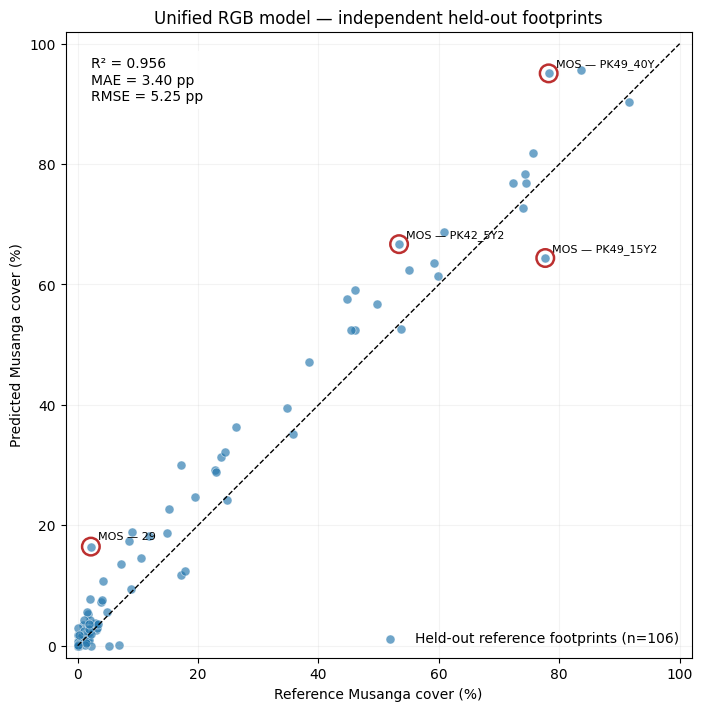

In [5]:
import matplotlib.pyplot as plt

top4=df.nlargest(4,'abs_cover_error_pp')[
    ['site','unit_type','unit_id','fold',
     'observed_cover_pp','predicted_cover_pp','cover_error_pp','abs_cover_error_pp']
].copy()
top4.to_csv(OUT/'04_RGB_unified_four_largest_errors.csv',index=False)
print('FOUR LARGEST ABSOLUTE COVER ERRORS — ALL RETAINED')
display(top4.round(2))

fig,ax=plt.subplots(figsize=(7.5,7),constrained_layout=True)
ax.scatter(df.observed_cover_pp,df.predicted_cover_pp,s=42,
           color='#2477ad',alpha=.66,edgecolors='white',
           linewidths=.45,label=f'Held-out reference footprints (n={len(df)})')
ax.plot([0,100],[0,100],'k--',lw=1)
for z in top4.itertuples():
    ax.scatter(z.observed_cover_pp,z.predicted_cover_pp,s=160,
               facecolors='none',edgecolors='#bc3030',
               linewidths=1.8,zorder=5)
    ax.annotate(f'{z.site} — {z.unit_id}',
                (z.observed_cover_pp,z.predicted_cover_pp),
                xytext=(5,5),textcoords='offset points',fontsize=8)
overall=SUMMARY.iloc[0]
ax.text(.04,.96,f'R² = {overall.R2:.3f}\nMAE = {overall.MAE_pp:.2f} pp\nRMSE = {overall.RMSE_pp:.2f} pp',
        transform=ax.transAxes,ha='left',va='top',fontsize=10,
        bbox=dict(facecolor='white',edgecolor='none',alpha=.87))
ax.set(xlim=(-2,102),ylim=(-2,102),
       xlabel='Reference Musanga cover (%)',
       ylabel='Predicted Musanga cover (%)',
       title='Unified RGB model — independent held-out footprints')
ax.set_aspect('equal',adjustable='box')
ax.grid(alpha=.15)
ax.legend(frameon=False,loc='lower right')
fig.savefig(OUT/'04_RGB_unified_equal_footprint_scatter.png',dpi=230,bbox_inches='tight')
plt.show()

## 04 — Combined cover classes and per-forest scatterplots

COMBINED COVER STRATA — EQUAL FOOTPRINTS


,cover_stratum,n,F1,IoU,MAE_pp,RMSE_pp,Bias_pp
0,0–1%,34,0.102,0.079,0.406,0.824,0.391
1,1–5%,29,0.522,0.399,2.145,3.546,1.590
2,5–20%,14,0.575,0.446,6.318,6.919,3.070
3,20–40%,9,0.841,0.728,5.798,6.580,5.507
4,>40%,20,0.906,0.831,7.173,8.584,5.493


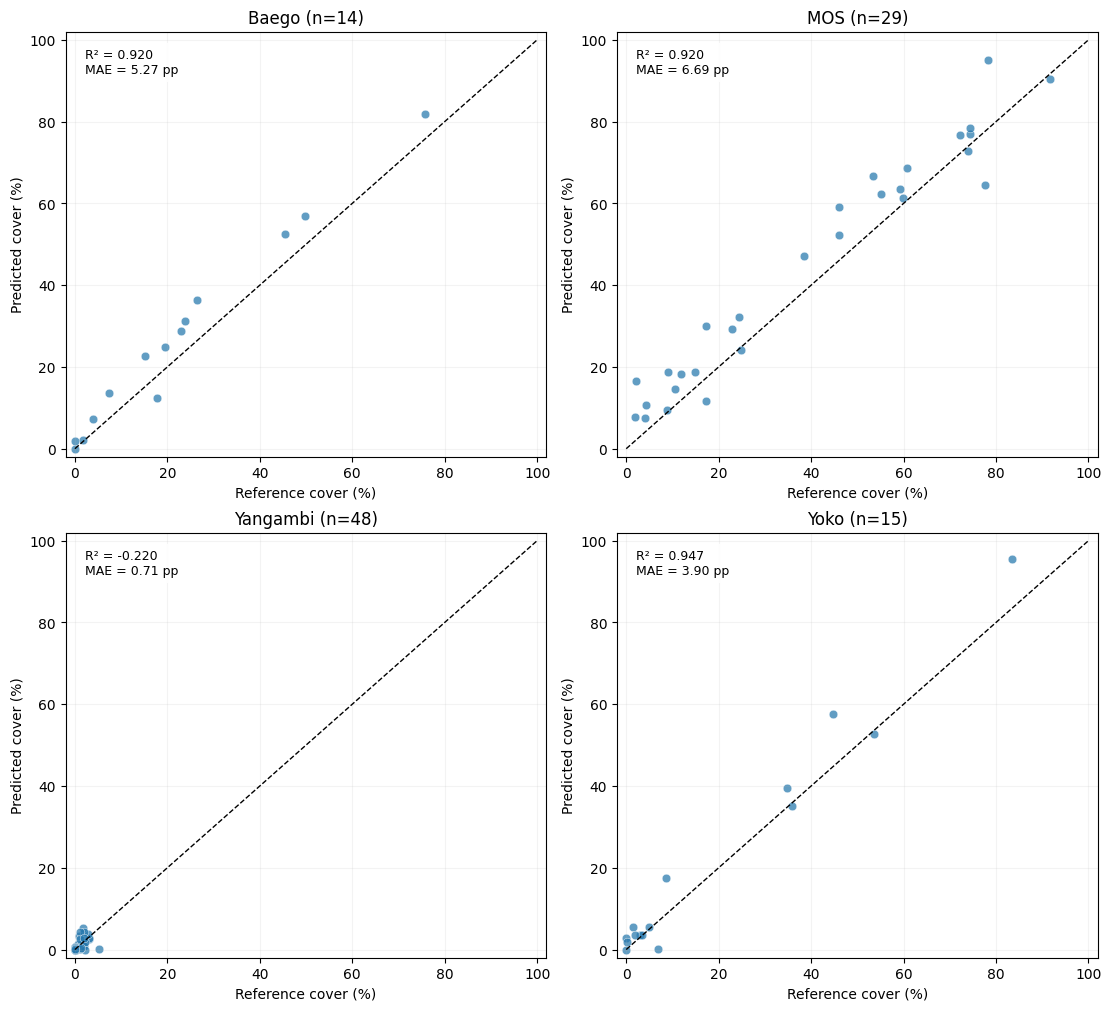

FINAL REPORT SAVED: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5/Outputs/04_unified_rgb_heldout_v5


In [6]:
# Stratify by reference cover without separating circle and plot shapes.
bins=[-.001,1,5,20,40,100.001]
labels=['0–1%','1–5%','5–20%','20–40%','>40%']
df['cover_stratum']=pd.cut(df.observed_cover_pp,bins=bins,
                           labels=labels,include_lowest=True)
strata=[]
for label,g in df.groupby('cover_stratum',observed=True):
    strata.append(dict(cover_stratum=str(label),**macro_metrics(g)))
STRATA=pd.DataFrame(strata)
STRATA.to_csv(OUT/'04_RGB_unified_combined_cover_strata.csv',index=False)
print('COMBINED COVER STRATA — EQUAL FOOTPRINTS')
display(STRATA[['cover_stratum','n','F1','IoU','MAE_pp','RMSE_pp','Bias_pp']].round(3))

# Forest panels: all footprints shown with the SAME symbol and weight.
sites=sorted(df.site.unique())
assert len(sites)==4
fig,axs=plt.subplots(2,2,figsize=(11,10),constrained_layout=True)
for ax,site in zip(axs.flat,sites):
    g=df[df.site.eq(site)]
    ax.scatter(g.observed_cover_pp,g.predicted_cover_pp,
               color='#2477ad',s=38,alpha=.72,edgecolors='white',linewidths=.4)
    ax.plot([0,100],[0,100],'k--',lw=1)
    m=macro_metrics(g)
    ax.text(.04,.96,f'R² = {m["R2"]:.3f}\nMAE = {m["MAE_pp"]:.2f} pp',
            transform=ax.transAxes,ha='left',va='top',fontsize=9,
            bbox=dict(facecolor='white',edgecolor='none',alpha=.85))
    ax.set(xlim=(-2,102),ylim=(-2,102),title=f'{site} (n={len(g)})',
           xlabel='Reference cover (%)',ylabel='Predicted cover (%)')
    ax.grid(alpha=.15)
fig.savefig(OUT/'04_RGB_unified_equal_footprint_scatter_by_forest.png',
            dpi=220,bbox_inches='tight')
plt.show()

manifest=dict(
    notebook='NB04_v5_unified_equal_footprint',
    model='unified',n_reference_footprints=106,
    source_counts={'circle':30,'plot':76},
    primary_weighting='Each held-out reference footprint contributes equally',
    original_data_folder=str(BASE),report_folder=str(OUT),
    source=source,inference_recomputed=True,inference_signature=signature,training_key=TRAIN['training_key'],threshold=.5,
    excluded_references=['Mixt1','Mixt2'],
    supplementary='Pixel-pooled classification metrics are secondary',
    exhaustive_plot_background_assumption='provisional, inherited from NB03'
)
(OUT/'04_RGB_unified_equal_footprint_manifest.json').write_text(json.dumps(manifest,indent=2))
print('FINAL REPORT SAVED:',OUT)

## Interpretation

Primary scores weight each of the 106 usable reference footprints equally. Binary cover uses a fixed probability threshold of 0.5; mean soft probability is retained separately. Undefined positive-class metrics are NaN, not silently treated as perfect or zero. Contradicted exhaustive labels are masked, and valid pixel fractions are reported. NB05 must use matched sensor support for modality comparisons. No model selection or training takes place here.
